# Coffee Orders – Cleaning & Visualization
Corrected version of the original notebook. Main fixes: real **Revenue** (Unit Price × Quantity) instead of a mislabeled Profit, `sum` instead of the default `mean` in pivots, no `fillna("")`, dates kept as datetime, merge validation.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
FILE = "./coffeeOrdersData.xlsx"

## 1. Load

In [3]:
sheets = pd.read_excel(FILE, sheet_name=["orders", "customers", "products"])
orders    = sheets["orders"]
customers = sheets["customers"]
products  = sheets["products"]

for name, df in sheets.items():
    print(f"{name:10s}", df.shape)

orders     (1000, 13)
customers  (1000, 9)
products   (48, 7)


## 2. Cleaning
The raw `Orders` sheet contains lookup columns (Country, Unit Price, Sales…) that are empty when read by pandas. We keep only the 5 real columns and rebuild everything from the `Customers` and `Products` tables.

In [5]:
orders = orders[["Order ID", "Order Date", "Customer ID", "Product ID", "Quantity"]].copy()
orders["Order Date"] = pd.to_datetime(orders["Order Date"])

customers = customers[["Customer ID", "Customer Name", "Email", "Country", "Loyalty Card"]]
products  = products[["Product ID", "Coffee Type", "Roast Type", "Size", "Unit Price", "Profit"]]

# validate= makes the merge fail loudly if the lookup tables contain duplicate keys
df = (orders
      .merge(customers, on="Customer ID", how="left", validate="m:1")
      .merge(products,  on="Product ID",  how="left", validate="m:1"))
df.shape

(1000, 14)

In [6]:
# Readable labels (note: Liberica, Light)
df["Coffee Type"] = df["Coffee Type"].map({"Rob": "Robusta", "Exc": "Excelsa",
                                           "Ara": "Arabica", "Lib": "Liberica"})
df["Roast Type"]  = df["Roast Type"].map({"L": "Light", "M": "Medium", "D": "Dark"})

# Business metrics
# 'Profit' in the Products sheet is profit PER UNIT, not sales.
df["Revenue"]      = df["Unit Price"] * df["Quantity"]
df["Total Profit"] = df["Profit"] * df["Quantity"]
df = df.drop(columns="Profit")

# Time features (kept as real dates, not strings)
df["Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Year"]  = df["Order Date"].dt.year

### Data quality checks

In [7]:
checks = {
    "rows": len(df),
    "fully duplicated rows": df.duplicated().sum(),
    "duplicated (Order ID, Product ID)": df.duplicated(["Order ID", "Product ID"]).sum(),
    "orders without matching customer": df["Country"].isna().sum(),
    "orders without matching product": df["Unit Price"].isna().sum(),
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "missing emails (kept as NaN)": df["Email"].isna().sum(),
}
pd.Series(checks, name="value").to_frame()

,value
rows,1000
fully duplicated rows,0
"duplicated (Order ID, Product ID)",1
orders without matching customer,0
orders without matching product,0
Quantity <= 0,0
missing emails (kept as NaN),206


In [8]:
df.info()
df[["Quantity", "Unit Price", "Revenue", "Total Profit"]].describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       1000 non-null   object        
 1   Order Date     1000 non-null   datetime64[ns]
 2   Customer ID    1000 non-null   object        
 3   Product ID     1000 non-null   object        
 4   Quantity       1000 non-null   int64         
 5   Customer Name  1000 non-null   object        
 6   Email          794 non-null    object        
 7   Country        1000 non-null   object        
 8   Loyalty Card   1000 non-null   object        
 9   Coffee Type    1000 non-null   object        
 10  Roast Type     1000 non-null   object        
 11  Size           1000 non-null   float64       
 12  Unit Price     1000 non-null   float64       
 13  Revenue        1000 non-null   float64       
 14  Total Profit   1000 non-null   float64       
 15  Month          1000 no

,Quantity,Unit Price,Revenue,Total Profit
count,1000.00,1000.00,1000.00,1000.00
mean,3.55,12.91,45.13,4.52
std,1.68,9.77,42.22,4.65
min,1.00,2.68,2.68,0.16
25%,2.00,5.37,15.54,1.40
50%,4.00,8.95,29.78,2.90
75%,5.00,15.85,59.70,6.07
max,6.00,36.46,218.73,28.43


## 3. KPIs

In [9]:
kpi = pd.Series({
    "Total revenue":   df["Revenue"].sum(),
    "Total profit":    df["Total Profit"].sum(),
    "Profit margin %": df["Total Profit"].sum() / df["Revenue"].sum() * 100,
    "Orders":          df["Order ID"].nunique(),
    "Customers":       df["Customer ID"].nunique(),
    "Avg order value": df.groupby("Order ID")["Revenue"].sum().mean(),
}).round(2)
kpi.to_frame("value")

,value
Total revenue,45134.26
Total profit,4520.22
Profit margin %,10.02
Orders,957.00
Customers,913.00
Avg order value,47.16


## 4. Visualization

**4.1 Monthly revenue and profit**

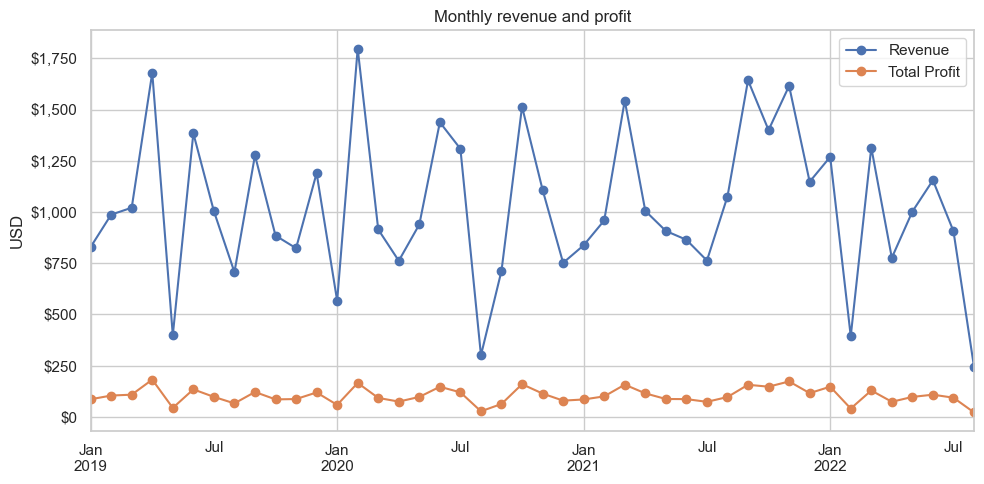

In [10]:
monthly = df.groupby("Month")[["Revenue", "Total Profit"]].sum()

ax = monthly.plot(marker="o", lw=1.5)
ax.set(title="Monthly revenue and profit", xlabel="", ylabel="USD")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout(); plt.show()

**4.2 Yearly revenue**

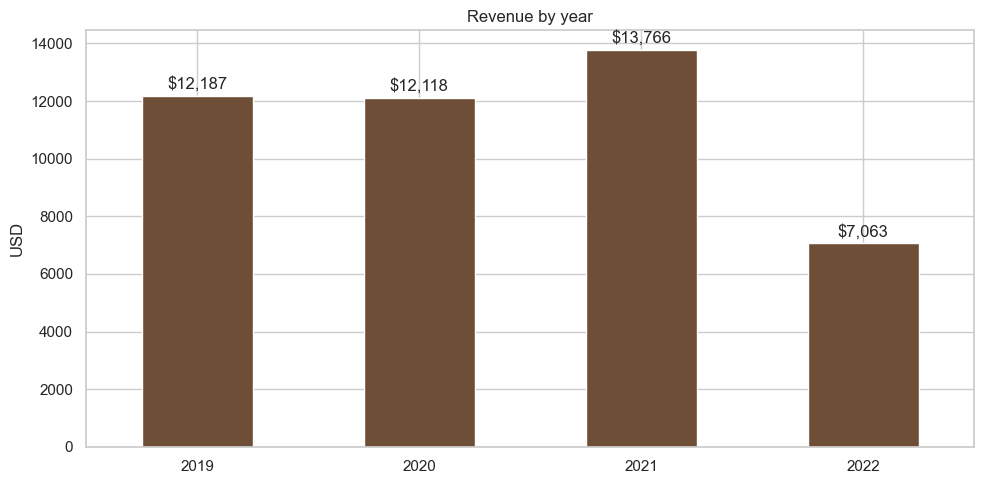

In [11]:
yearly = df.groupby("Year")["Revenue"].sum()
ax = yearly.plot(kind="bar", color="#6F4E37", rot=0)
ax.set(title="Revenue by year", xlabel="", ylabel="USD")
ax.bar_label(ax.containers[0], fmt="${:,.0f}", padding=3)
plt.tight_layout(); plt.show()

**4.3 Revenue by coffee type, country and roast**

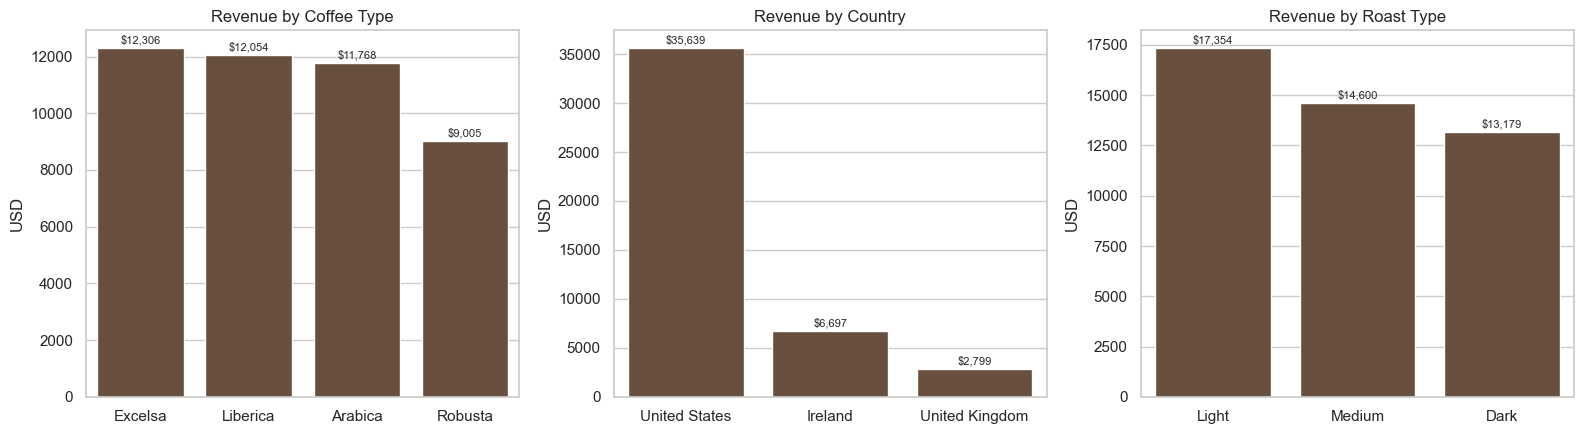

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Coffee Type", "Country", "Roast Type"]):
    s = df.groupby(col)["Revenue"].sum().sort_values(ascending=False)
    sns.barplot(x=s.index, y=s.values, ax=ax, color="#6F4E37")
    ax.set(title=f"Revenue by {col}", xlabel="", ylabel="USD")
    ax.bar_label(ax.containers[0], fmt="${:,.0f}", padding=2, fontsize=8)
plt.tight_layout(); plt.show()

**4.4 Revenue: country × coffee type** (sum, not mean)

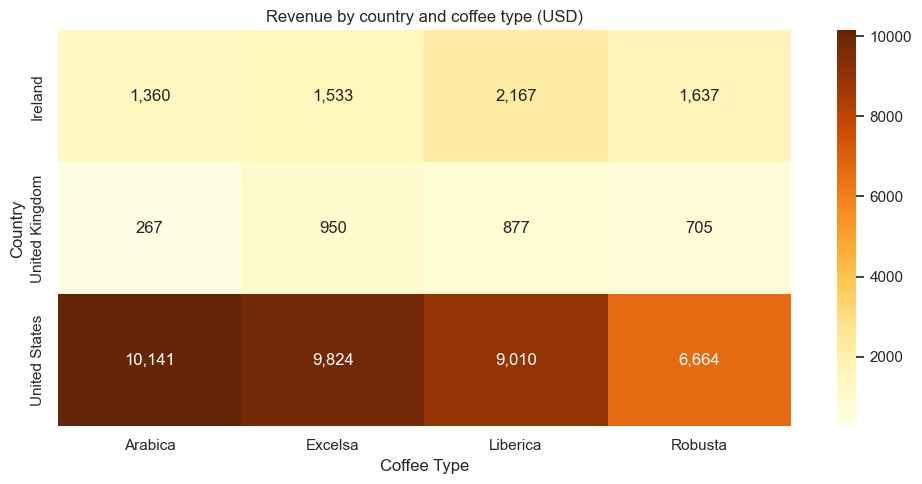

In [13]:
pivot = df.pivot_table(values="Revenue", index="Country", columns="Coffee Type",
                       aggfunc="sum", fill_value=0)
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlOrBr")
plt.title("Revenue by country and coffee type (USD)")
plt.tight_layout(); plt.show()

**4.5 Monthly revenue trend by coffee type**

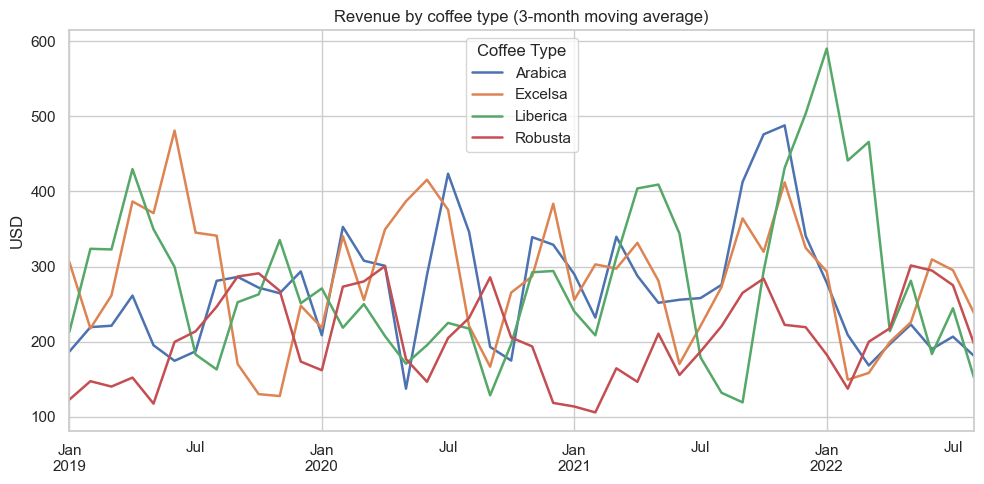

In [14]:
trend = (df.groupby(["Month", "Coffee Type"])["Revenue"].sum()
           .unstack("Coffee Type").fillna(0))
ax = trend.rolling(3, min_periods=1).mean().plot(lw=1.8)   # 3-month moving average
ax.set(title="Revenue by coffee type (3-month moving average)", xlabel="", ylabel="USD")
plt.tight_layout(); plt.show()

**4.6 Top 10 customers and loyalty card effect**

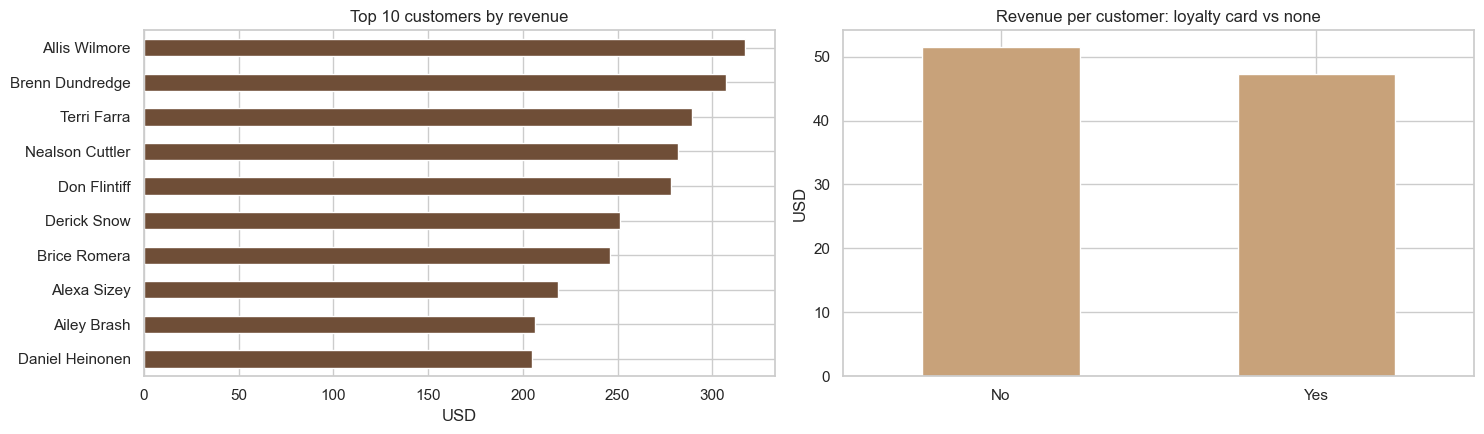

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

top = df.groupby("Customer Name")["Revenue"].sum().nlargest(10).sort_values()
top.plot(kind="barh", ax=axes[0], color="#6F4E37")
axes[0].set(title="Top 10 customers by revenue", ylabel="", xlabel="USD")

loyal = df.groupby("Loyalty Card").agg(revenue=("Revenue", "sum"),
                                       customers=("Customer ID", "nunique"))
(loyal["revenue"] / loyal["customers"]).plot(kind="bar", ax=axes[1], rot=0, color="#C8A27A")
axes[1].set(title="Revenue per customer: loyalty card vs none", xlabel="", ylabel="USD")
plt.tight_layout(); plt.show()

## 5. Export the clean dataset (e.g. for Power BI)

In [16]:
df.to_csv("coffee_orders_clean.csv", index=False)